# Task 1
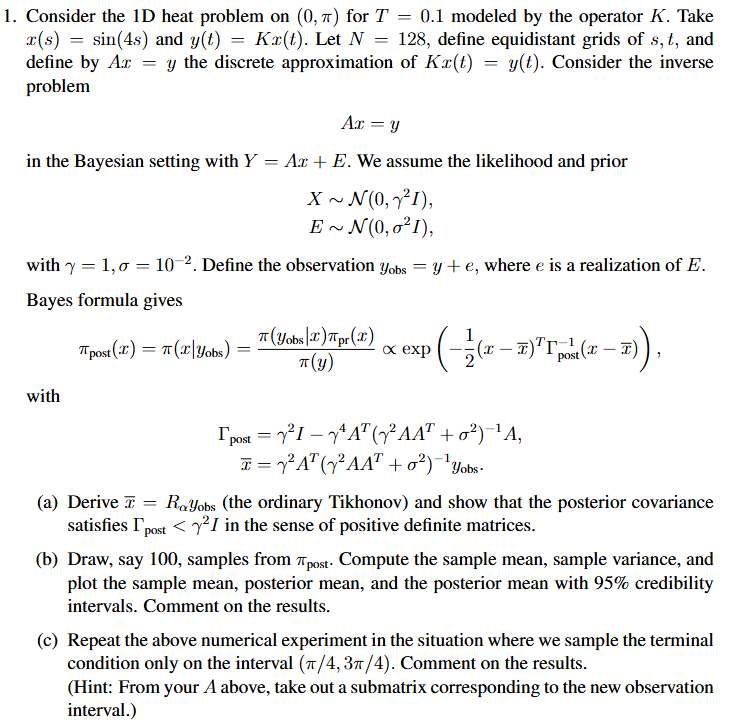

In [67]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import numpy as np
from scipy.fft import dst, idst
import matplotlib.pyplot as plt
import numpy.typing as npt
import matplotlib as mpl
from tqdm.auto import tqdm

In [68]:
OUTPUT_DIR = Path("./output")
OUTPUT_DIR.mkdir(exist_ok=True)

mm = 1 / 25.4  # mm in inches
## #context layout(size => size.width.mm())
PAPER_WIDTH_IN = 259.3 * mm
TITLE_SIZE_PT = 18

sns.set_theme(context="talk", style="whitegrid")
EXPORT_DPI = 600


In [69]:
# Based on: https://stackoverflow.com/a/29261252/5036246
def sci_notation(number, sig_fig=2, latex_style=True, omit_coeff_if_unity=True):
    ret_string = "{0:.{1:d}e}".format(number, sig_fig)
    a, b = ret_string.split("e")

    # Calculate factor part
    factor = ""
    joiner = ""
    if omit_coeff_if_unity and float(a) == 1.0:
        factor = ""
        joiner = ""
    else:
        factor = a
        joiner = "×"

    # Calculate exponent part
    b = int(b)
    exponent = ""
    if latex_style:
        exponent = f"10^{{{str(b)}}}"
    else:
        exponent = f"10^{str(b)}"

    return factor + joiner + exponent

## 1.b
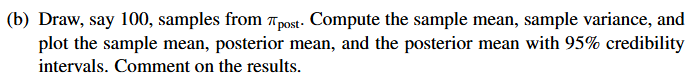

In [70]:
def forward_heat_operator(N_int: int, T: float) -> npt.NDArray:
    """
    Creates the discrete forward operator A for the 1D heat equation.

    The operator maps the initial state u(s, 0) to the final state u(s, T).
    It is constructed using the Discrete Sine Transform (DST).

    Note that the spatial domain is assumed to be (0, π).

    Arguments:
        N_int: The number of internal grid points.
        T: The final time.

    Returns:
        Matrix A of shape (N_int, N_int) that can be applied to the _internal_ state vector.
    """

    k = np.arange(N_int) + 1  # Wavenumbers
    decay_factors = np.exp(-(k**2) * T)  # Decay factors for each mode

    A = np.zeros((N_int, N_int))
    for j in range(N_int):
        # Basis vector
        e_j = np.zeros(N_int)
        e_j[j] = 1.0

        # Type I DST corresponding to sine series expansion
        coeffs = dst(e_j, type=1, norm="ortho")
        decayed_coeffs = decay_factors * coeffs
        col_j = idst(decayed_coeffs, type=1, norm="ortho")

        A[:, j] = col_j

    return A


# Parameters
N = 128
N_int = N - 2
T = 0.1
a = 0
b = np.pi

# Get spatial discretisation
s_grid = np.linspace(a, b, N, endpoint=True)
s_internal = s_grid[1:-1]  # Internal points only


def analytical_1(s: npt.NDArray) -> npt.NDArray:
    return np.sin(4 * s)


x_initial = analytical_1(s_grid)
x_initial_internal = x_initial[1:-1]

# Get operator
A = forward_heat_operator(N_int, T)
y_final_numeric_internal = A @ x_initial_internal

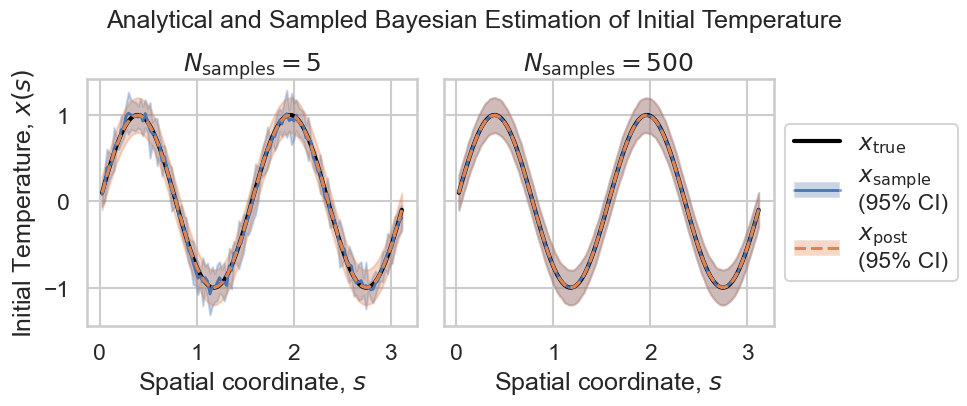

In [71]:
np.random.seed(42)

gamma = 1e-1
sigma = 1e-3

N_simulations = 10
I = np.eye(*A.shape)

fig, (ax_coarse, ax_fine) = plt.subplots(
    1, 2, figsize=(PAPER_WIDTH_IN, 4.5), sharey=True, sharex=True
)
for N_simulations, ax in [(5, ax_coarse), (500, ax_fine)]:
    posterior_covariance = (
        gamma**2 * I
        + gamma**4 * A.T @ np.linalg.inv(gamma**2 * A @ A.T + sigma**2 * I) @ A
    )
    posterior_mean = (
        gamma**2
        * A.T
        @ np.linalg.inv(gamma**2 * A @ A.T + sigma**2 * I)
        @ y_final_numeric_internal
    )
    posterior_variance = np.diag(posterior_covariance)
    x_sample = np.random.multivariate_normal(
        posterior_mean, posterior_covariance, size=N_simulations
    )

    sample_mean = np.mean(x_sample, axis=0)
    sample_variance = np.var(x_sample, axis=0)

    ax.plot(
        s_internal,
        x_initial_internal,
        color="black",
        linewidth=3.0,
        label="Initial condition",
    )
    ax.plot(s_internal, sample_mean, color="C0", lw=2.0, label="Sample mean")
    ax.plot(s_internal, posterior_mean, color="C1", ls="--", label="Posterior mean")

    # Plot 95% credible intervals
    sample_upper_bound = sample_mean + 1.96 * np.sqrt(sample_variance)
    sample_lower_bound = sample_mean - 1.96 * np.sqrt(sample_variance)
    posterior_upper_bound = posterior_mean + 1.96 * np.sqrt(posterior_variance)
    posterior_lower_bound = posterior_mean - 1.96 * np.sqrt(posterior_variance)
    ax.fill_between(
        s_internal, sample_lower_bound, sample_upper_bound, color="C0", alpha=0.3
    )
    ax.fill_between(
        s_internal, posterior_lower_bound, posterior_upper_bound, color="C1", alpha=0.3
    )

    ax.set_title(f"$N_\\mathrm{{samples}} = {N_simulations}$")

legend_elements = [
    mpl.lines.Line2D([0], [0], color="black", linewidth=3.0),
    (
        mpl.lines.Line2D([0], [0], color="C0", linewidth=2.0, ls="-"),
        mpl.patches.Patch(facecolor="C0", alpha=0.3),
    ),
    (
        mpl.lines.Line2D([0], [0], color="C1", ls="--"),
        mpl.patches.Patch(facecolor="C1", alpha=0.3),
    ),
]

legend_labels = [
    "$x_\\mathrm{true}$",
    "$x_\\mathrm{sample}$\n(95% CI)",
    "$x_\\mathrm{post}$\n(95% CI)",
]

ax.legend(legend_elements, legend_labels, loc="center left", bbox_to_anchor=(1, 0.5))

ax_coarse.set_xlabel("Spatial coordinate, $s$")
ax_fine.set_xlabel("Spatial coordinate, $s$")
ax_coarse.set_ylabel("Initial Temperature, $x(s)$")

fig.suptitle(
    "Analytical and Sampled Bayesian Estimation of Initial Temperature",
    fontsize=TITLE_SIZE_PT,
    y=0.92,
)
fig.tight_layout()
plt.savefig(OUTPUT_DIR / "1_b.png", dpi=EXPORT_DPI, bbox_inches="tight")

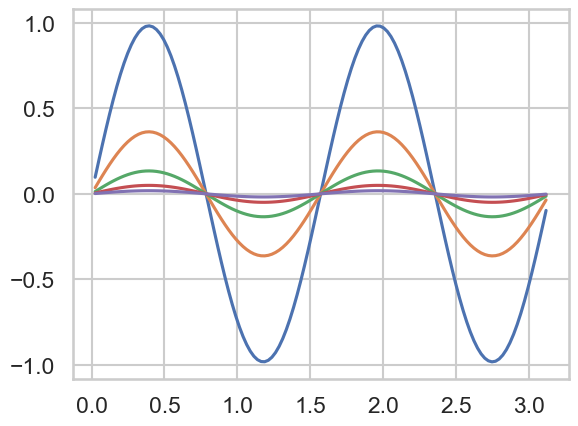

In [72]:
# Visualise temperature progression
for T_final in np.linspace(0.001, 0.25, 5):
    A_original = forward_heat_operator(N_int, T_final)
    y = A_original @ x_initial_internal

    plt.plot(s_internal, y, label=f"T={T_final:.3f}")

## 1.c
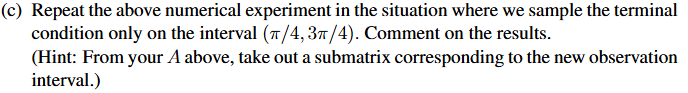

In [73]:
# Parameters
N = 128
N_int = N - 2
T = 0.1
a = 0
b = np.pi

gamma = 1e-1
sigma = 1e-3

# Get spatial discretisation
s_grid = np.linspace(a, b, N, endpoint=True)
s_internal = s_grid[1:-1]  # Internal points only


def analytical_1(s: npt.NDArray) -> npt.NDArray:
    return np.sin(4 * s)


x_initial = analytical_1(s_grid)
x_initial_internal = x_initial[1:-1]

# Get operator
A = forward_heat_operator(N_int, T)

# We only observe some of the terminal conditions
obs_min = np.pi / 4
obs_max = 3 / 4 * np.pi
obs_mask = (obs_min < s_internal) & (s_internal < obs_max)

y_full = A @ x_initial_internal
y_obs = y_full[obs_mask]

A_obs = A[obs_mask, :]  # Observed rows only

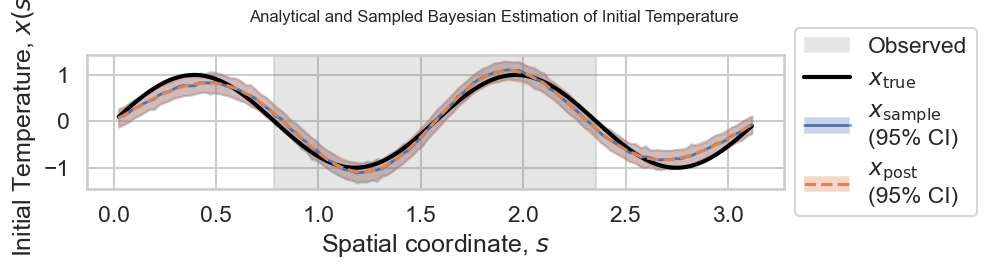

In [74]:
M = A_obs.shape[0]  # Number of observations
I_obs = np.eye(M)
I_state = np.eye(N_int)

posterior_mean_obs = (
    gamma**2
    * A_obs.T
    @ np.linalg.inv(gamma**2 * A_obs @ A_obs.T + sigma**2 * I_obs)
    @ y_obs
)
posterior_covariance_obs = (
    gamma**2 * I_state
    + gamma**4
    * A_obs.T
    @ np.linalg.inv(gamma**2 * A_obs @ A_obs.T + sigma**2 * I_obs)
    @ A_obs
)
posterior_variance_obs = np.diag(posterior_covariance_obs)

# Sample posterior
N_simulations = 50
np.random.seed(42)
x_samples_obs = np.random.multivariate_normal(
    posterior_mean_obs, posterior_covariance_obs, size=N_simulations
)

sample_mean_obs = np.mean(x_samples_obs, axis=0)
sample_variance_obs = np.var(x_samples_obs, axis=0)

fig, ax = plt.subplots(figsize=(PAPER_WIDTH_IN, 3))
ax.plot(
    s_internal,
    x_initial_internal,
    color="black",
    linewidth=3.0,
    label="Initial condition",
)
ax.plot(s_internal, sample_mean_obs, color="C0", lw=2.0, label="Sample mean")
ax.plot(s_internal, posterior_mean_obs, color="C1", ls="--", label="Posterior mean")

# Plot 95% credible intervals
sample_upper_bound = sample_mean_obs + 1.96 * np.sqrt(sample_variance_obs)
sample_lower_bound = sample_mean_obs - 1.96 * np.sqrt(sample_variance_obs)
posterior_upper_bound = posterior_mean_obs + 1.96 * np.sqrt(posterior_variance_obs)
posterior_lower_bound = posterior_mean_obs - 1.96 * np.sqrt(posterior_variance_obs)
ax.fill_between(
    s_internal, sample_lower_bound, sample_upper_bound, color="C0", alpha=0.3
)
ax.fill_between(
    s_internal, posterior_lower_bound, posterior_upper_bound, color="C1", alpha=0.3
)

# Plot observation region
ax.axvspan(obs_min, obs_max, color="gray", alpha=0.2, label="Observation region")

legend_elements = [
    mpl.patches.Patch(facecolor="gray", alpha=0.2),
    mpl.lines.Line2D([0], [0], color="black", linewidth=3.0),
    (
        mpl.lines.Line2D([0], [0], color="C0", linewidth=2.0, ls="-"),
        mpl.patches.Patch(facecolor="C0", alpha=0.3),
    ),
    (
        mpl.lines.Line2D([0], [0], color="C1", ls="--"),
        mpl.patches.Patch(facecolor="C1", alpha=0.3),
    ),
]

legend_labels = [
    "Observed",
    "$x_\\mathrm{true}$",
    "$x_\\mathrm{sample}$\n(95% CI)",
    "$x_\\mathrm{post}$\n(95% CI)",
]

ax.legend(legend_elements, legend_labels, loc="center left", bbox_to_anchor=(1, 0.5))

ax.set_xlabel("Spatial coordinate, $s$")
ax.set_ylabel("Initial Temperature, $x(s)$")

fig.suptitle(
    "Analytical and Sampled Bayesian Estimation of Initial Temperature",
    fontsize=12,
    y=0.92,
)
fig.tight_layout()
plt.savefig(OUTPUT_DIR / "1_c.png", dpi=EXPORT_DPI, bbox_inches="tight")

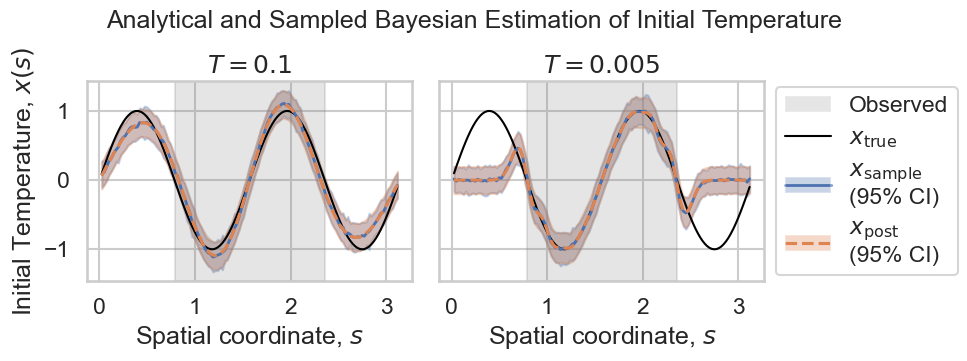

In [75]:
# Double plot

# Parameters
N = 128
N_int = N - 2
T = 0.1
a = 0
b = np.pi

gamma = 1e-1
sigma = 1e-3

# Get spatial discretisation
s_grid = np.linspace(a, b, N, endpoint=True)
s_internal = s_grid[1:-1]  # Internal points only


def analytical_1(s: npt.NDArray) -> npt.NDArray:
    return np.sin(4 * s)


x_initial = analytical_1(s_grid)
x_initial_internal = x_initial[1:-1]

np.random.seed(42)

fig, (ax_long, ax_short) = plt.subplots(
    1, 2, figsize=(PAPER_WIDTH_IN, 4.0), sharey=True, sharex=True
)
for T, ax in [(0.1, ax_long), (0.005, ax_short)]:
    # Get operator
    A = forward_heat_operator(N_int, T)

    # We only observe some of the terminal conditions
    obs_min = np.pi / 4
    obs_max = 3 / 4 * np.pi
    obs_mask = (obs_min < s_internal) & (s_internal < obs_max)

    y_full = A @ x_initial_internal
    y_obs = y_full[obs_mask]

    A_obs = A[obs_mask, :]  # Observed rows only

    M = A_obs.shape[0]  # Number of observations
    I_obs = np.eye(M)
    I_state = np.eye(N_int)

    posterior_mean_obs = (
        gamma**2
        * A_obs.T
        @ np.linalg.inv(gamma**2 * A_obs @ A_obs.T + sigma**2 * I_obs)
        @ y_obs
    )
    posterior_covariance_obs = (
        gamma**2 * I_state
        + gamma**4
        * A_obs.T
        @ np.linalg.inv(gamma**2 * A_obs @ A_obs.T + sigma**2 * I_obs)
        @ A_obs
    )
    posterior_variance_obs = np.diag(posterior_covariance_obs)

    # Sample posterior
    N_simulations = 50
    x_samples_obs = np.random.multivariate_normal(
        posterior_mean_obs, posterior_covariance_obs, size=N_simulations
    )

    sample_mean_obs = np.mean(x_samples_obs, axis=0)
    sample_variance_obs = np.var(x_samples_obs, axis=0)

    ax.plot(
        s_internal,
        x_initial_internal,
        color="black",
        linewidth=1.5,
        label="Initial condition",
    )
    ax.plot(s_internal, sample_mean_obs, color="C0", lw=2.0, label="Sample mean")
    ax.plot(s_internal, posterior_mean_obs, color="C1", ls="--", label="Posterior mean")

    # Plot 95% credible intervals
    sample_upper_bound = sample_mean_obs + 1.96 * np.sqrt(sample_variance_obs)
    sample_lower_bound = sample_mean_obs - 1.96 * np.sqrt(sample_variance_obs)
    posterior_upper_bound = posterior_mean_obs + 1.96 * np.sqrt(posterior_variance_obs)
    posterior_lower_bound = posterior_mean_obs - 1.96 * np.sqrt(posterior_variance_obs)
    ax.fill_between(
        s_internal, sample_lower_bound, sample_upper_bound, color="C0", alpha=0.3
    )
    ax.fill_between(
        s_internal, posterior_lower_bound, posterior_upper_bound, color="C1", alpha=0.3
    )

    # Plot observation region
    ax.axvspan(obs_min, obs_max, color="gray", alpha=0.2, label="Observation region")

    ax.set_title(f"$T = {T}$")

legend_elements = [
    mpl.patches.Patch(facecolor="gray", alpha=0.2),
    mpl.lines.Line2D([0], [0], color="black", linewidth=1.5),
    (
        mpl.lines.Line2D([0], [0], color="C0", linewidth=2.0, ls="-"),
        mpl.patches.Patch(facecolor="C0", alpha=0.3),
    ),
    (
        mpl.lines.Line2D([0], [0], color="C1", ls="--"),
        mpl.patches.Patch(facecolor="C1", alpha=0.3),
    ),
]

legend_labels = [
    "Observed",
    "$x_\\mathrm{true}$",
    "$x_\\mathrm{sample}$\n(95% CI)",
    "$x_\\mathrm{post}$\n(95% CI)",
]

ax.legend(legend_elements, legend_labels, loc="center left", bbox_to_anchor=(1, 0.5))

ax_short.set_xlabel("Spatial coordinate, $s$")
ax_long.set_xlabel("Spatial coordinate, $s$")
ax_long.set_ylabel("Initial Temperature, $x(s)$")

fig.suptitle(
    "Analytical and Sampled Bayesian Estimation of Initial Temperature",
    fontsize=TITLE_SIZE_PT,
    y=0.92,
)
fig.tight_layout()
plt.savefig(OUTPUT_DIR / "1_c_double.png", dpi=EXPORT_DPI, bbox_inches="tight")

# 2
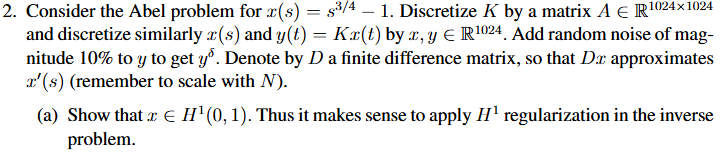
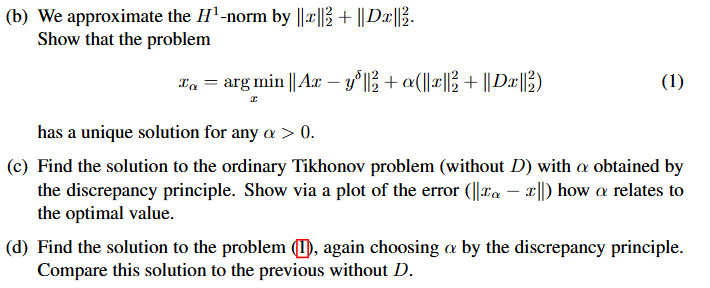

## 2.c
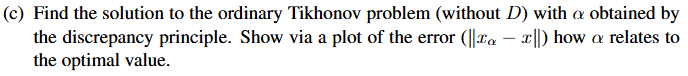

Achieved noise level: 2.2372739635471577


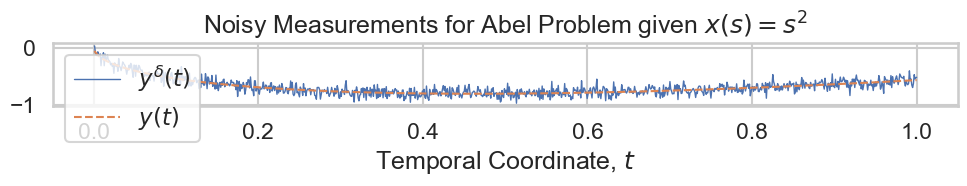

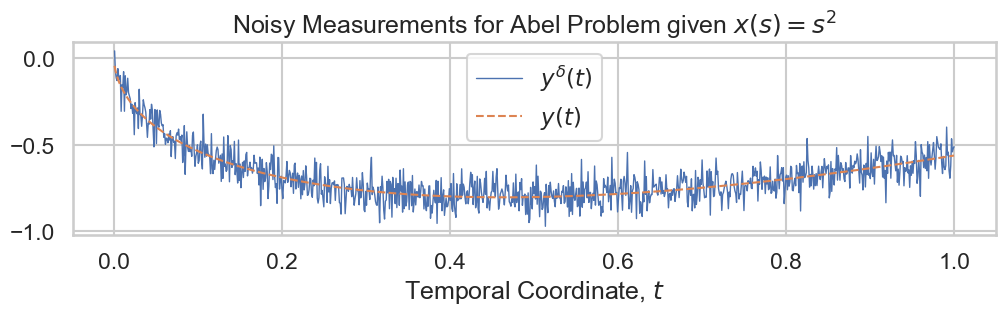

In [76]:
# Abel Problem
N = 1024
a = 0
b = 1
h = (b - a) / N
s = a + (np.arange(N) + 0.5) * h
t = s + h / 2  # Shift t values to prevent singularity at t=s

s_mesh, t_mesh = np.meshgrid(s, t)

A = np.zeros((N, N))
indices = s_mesh < t_mesh  # Select according to integral
A[indices] = h / np.sqrt((t_mesh[indices] - s_mesh[indices]))


def x_2_func(s):
    return s ** (3 / 4) - 1


def grad_x_2_func(s):
    return (3 / 4) * s ** (-1 / 4)


x_true = x_2_func(s)
grad_x_true = grad_x_2_func(s)
y_true = A @ x_true

# Add noise, 10%
target_noise_level = 0.10
unscaled_noise = np.random.randn(*y_true.shape)
unscaled_noise_level = np.linalg.norm(unscaled_noise)
noise_coeff = target_noise_level * np.linalg.norm(y_true) / unscaled_noise_level
noise = noise_coeff * unscaled_noise
noise_level = np.linalg.norm(noise)
print(f"Achieved noise level: {noise_level}")
y_noisy = y_true + noise

# Plot noisy measurements
plt.figure(figsize=(PAPER_WIDTH_IN, 2.2))
plt.plot(t, y_noisy, label="$y^δ(t)$", lw=1)
plt.plot(t, y_true, label="$y(t)$", lw=1.5, ls="--")
plt.title("Noisy Measurements for Abel Problem given $x(s) = s^2$")
plt.xlabel("Temporal Coordinate, $t$")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "2_a.png", dpi=600, bbox_inches="tight")
display(plt.gcf())

plt.gcf().set_size_inches(PAPER_WIDTH_IN, 3.5)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "2_a_large.png", dpi=600, bbox_inches="tight")

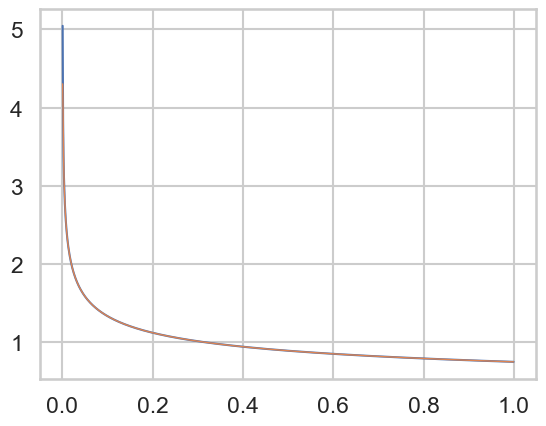

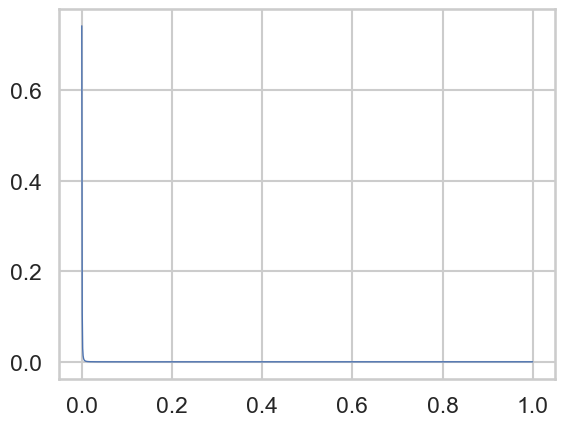

In [77]:
def create_differentiation_matrix(n: int, h: float) -> npt.NDArray:
    D = np.zeros((n, n))

    # Use forward difference for the first point
    D[0, 0] = -1.0 / h
    D[0, 1] = 1.0 / h

    # Central difference for interior points
    for i in range(1, n - 1):
        D[i, i - 1] = -0.5 / h
        D[i, i + 1] = 0.5 / h

    # Backward difference for the last point
    D[n - 1, n - 2] = -1.0 / h
    D[n - 1, n - 1] = 1.0 / h

    return D


D = create_differentiation_matrix(N, h)

grad_x_estimate = D @ x_true
plt.plot(s, grad_x_true, label="True Gradient", lw=1.5)
plt.plot(s, grad_x_estimate, label="Estimated Gradient", lw=1)
plt.figure()
plt.plot(s, np.abs(grad_x_true - grad_x_estimate), label="Absolute Error", lw=1)

In [78]:
def tikhonov_ordinary(alpha: float) -> npt.NDArray:
    n = A.shape[1]
    x_alpha = np.linalg.inv(A.T @ A + alpha * np.eye(n)) @ A.T @ y_noisy
    return x_alpha


def tikhonov_generalised_smoothness(alpha: float) -> npt.NDArray:
    # TODO: Derive in report
    n = A.shape[1]
    x_alpha = np.linalg.inv(A.T @ A + alpha * (np.eye(n) + D.T @ D)) @ A.T @ y_noisy
    return x_alpha


def F_1(alpha, x_alpha):
    return np.linalg.norm(A @ x_alpha - y_noisy)


alphas = np.linspace(0, 0.2, 200)
data = []
for alpha in tqdm(alphas):
    x_alpha_ordinary = tikhonov_ordinary(alpha)
    F_1_val_ordinary = F_1(alpha, x_alpha_ordinary)
    x_diff_ordinary = x_alpha_ordinary - x_true

    x_alpha_generalised = tikhonov_generalised_smoothness(alpha)
    F_1_val_generalised = F_1(alpha, x_alpha_generalised)
    x_diff_generalised = x_alpha_generalised - x_true

    data.append(
        {
            "alpha": alpha,
            "F_1_ordinary": F_1_val_ordinary,
            "x_alpha_ordinary": x_alpha_ordinary,
            "x_diff_ordinary": x_diff_ordinary,
            "x_diff_ordinary_L2": np.linalg.norm(x_diff_ordinary),
            "F_1_generalised": F_1_val_generalised,
            "x_alpha_generalised": x_alpha_generalised,
            "x_diff_generalised": x_diff_generalised,
            "x_diff_generalised_L2": np.linalg.norm(x_diff_generalised),
        }
    )

df = pd.DataFrame(data)

df_2c = df.copy()


100%|██████████| 200/200 [00:37<00:00,  5.37it/s]


In [79]:
# Safety factor, referred to as nu in lecture notes
safety_factor = 1.05

# Find optimal alpha for ordinary Tikhonov
df_2c["ordinary_search_target"] = df_2c["F_1_ordinary"] - safety_factor * noise_level
idx_ordinary = df_2c["ordinary_search_target"].abs().idxmin()
df_2c["generalised_search_target"] = (
    df_2c["F_1_generalised"] - safety_factor * noise_level
)
idx_generalised = df_2c["generalised_search_target"].abs().idxmin()
idx_ordinary_true = df_2c["x_diff_ordinary_L2"].abs().idxmin()
idx_generalised_true = df_2c["x_diff_generalised_L2"].abs().idxmin()
print(
    f"Optimal alpha (ordinary): Estimate: {df_2c.iloc[idx_ordinary]['alpha']}, True min: {df_2c.iloc[idx_ordinary_true]['alpha']}"
)
print(
    f"Optimal alpha (generalised): Estimate: {df_2c.iloc[idx_generalised]['alpha']}, True min: {df_2c.iloc[idx_generalised_true]['alpha']}"
)

ordinary_estimate_alpha = df_2c.iloc[idx_ordinary]["alpha"]
ordinary_estimate_residual = df_2c.iloc[idx_ordinary]["F_1_ordinary"]
ordinary_estimate_error = df_2c.iloc[idx_ordinary]["x_diff_ordinary_L2"]
generalised_estimate_alpha = df_2c.iloc[idx_generalised]["alpha"]
generalised_estimate_residual = df_2c.iloc[idx_generalised]["F_1_generalised"]
generalised_estimate_error = df_2c.iloc[idx_generalised]["x_diff_generalised_L2"]
ordinary_true_alpha = df_2c.iloc[idx_ordinary_true]["alpha"]
ordinary_true_residual = df_2c.iloc[idx_ordinary_true]["F_1_ordinary"]
ordinary_true_error = df_2c.iloc[idx_ordinary_true]["x_diff_ordinary_L2"]
generalised_true_alpha = df_2c.iloc[idx_generalised_true]["alpha"]
generalised_true_residual = df_2c.iloc[idx_generalised_true]["F_1_generalised"]
generalised_true_error = df_2c.iloc[idx_generalised_true]["x_diff_generalised_L2"]

ordinary_best_x = df_2c.iloc[idx_ordinary]["x_alpha_ordinary"]
ordinary_best_alpha = df_2c.iloc[idx_ordinary]["alpha"]

Optimal alpha (ordinary): Estimate: 0.07839195979899498, True min: 0.09748743718592966
Optimal alpha (generalised): Estimate: 0.006030150753768845, True min: 0.0010050251256281408


[]

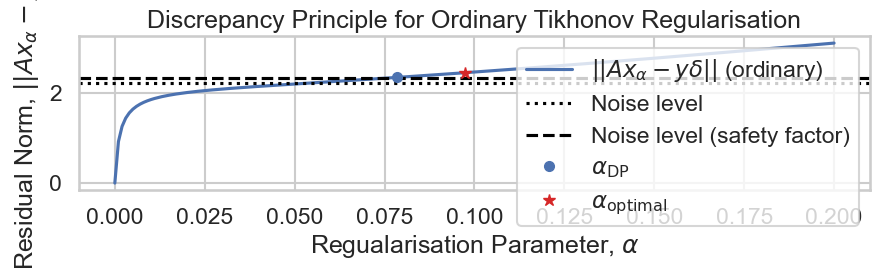

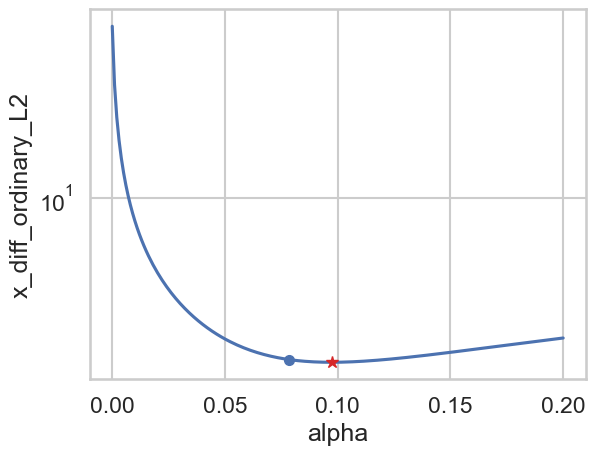

In [80]:
# Discrepancy plot
plt.figure(figsize=(PAPER_WIDTH_IN, 2))
sns.lineplot(data=df, x="alpha", y="F_1_ordinary", label="$||Ax_α- yδ||$ (ordinary)")
# sns.lineplot(data=df, x="alpha", y="F_1_generalised")

plt.axhline(noise_level, color="black", ls=":", label="Noise level")
plt.axhline(
    noise_level * safety_factor,
    color="black",
    ls="--",
    label="Noise level (safety factor)",
)

plt.plot(
    ordinary_estimate_alpha,
    ordinary_estimate_residual,
    "o",
    color="C0",
    markersize=7,
    label="$α_\\mathrm{DP}$",
)
plt.plot(
    ordinary_true_alpha,
    ordinary_true_residual,
    "*",
    color="tab:red",
    markersize=9,
    label="$α_\\mathrm{optimal}$",
)
plt.legend()

plt.title("Discrepancy Principle for Ordinary Tikhonov Regularisation")
plt.xlabel("Regualarisation Parameter, $α$")
plt.ylabel("Residual Norm, $||Ax_α - y^δ||$")

plt.figure()
sns.lineplot(data=df, x="alpha", y="x_diff_ordinary_L2")
plt.plot(
    ordinary_estimate_alpha,
    ordinary_estimate_error,
    "o",
    color="C0",
    markersize=7,
    label="$α_\\mathrm{DP}$",
)
plt.plot(
    ordinary_true_alpha,
    ordinary_true_error,
    "*",
    color="tab:red",
    markersize=9,
    label="$α_\\mathrm{optimal}$",
)
# sns.lineplot(data=df, x="alpha", y="x_diff_generalised_L2")
plt.semilogy()

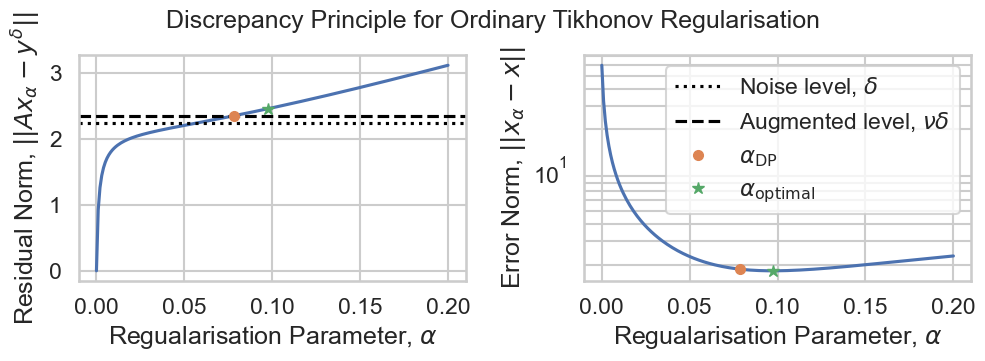

In [81]:
# Discrepancy plot
fig, (ax_resid, ax_error) = plt.subplots(1, 2, figsize=(PAPER_WIDTH_IN, 4.0))

sns.lineplot(ax=ax_resid, data=df_2c, x="alpha", y="F_1_ordinary")
# sns.lineplot(data=df_2c, x="alpha", y="F_1_generalised")

ax_resid.axhline(noise_level, color="black", ls=":", label="Noise level, $δ$")
ax_resid.axhline(
    noise_level * safety_factor, color="black", ls="--", label="Augmented level, $νδ$"
)

ax_resid.plot(
    ordinary_estimate_alpha,
    ordinary_estimate_residual,
    "o",
    color="C1",
    markersize=7,
    label="$α_\\mathrm{DP}$",
)
ax_resid.plot(
    ordinary_true_alpha,
    ordinary_true_residual,
    "*",
    color="C2",
    markersize=9,
    label="$α_\\mathrm{optimal}$",
)

ax_resid.set_xlabel("Regualarisation Parameter, $α$")
ax_resid.set_ylabel("Residual Norm, $||Ax_α - y^δ||$")

sns.lineplot(ax=ax_error, data=df_2c, x="alpha", y="x_diff_ordinary_L2", color="C0")
ax_error.plot(
    ordinary_estimate_alpha, ordinary_estimate_error, "o", color="C1", markersize=7
)
ax_error.plot(ordinary_true_alpha, ordinary_true_error, "*", color="C2", markersize=9)
# sns.lineplot(data=df_2c, x="alpha", y="x_diff_generalised_L2")
ax_error.set_yscale("log")
ax_error.grid(axis="y", which="both")
ax_error.set_xlabel("Regualarisation Parameter, $α$")
ax_error.set_ylabel("Error Norm, $||x_α - x||$")

# Get legends and handles from both axes
handles1, labels1 = ax_resid.get_legend_handles_labels()
handles2, labels2 = ax_error.get_legend_handles_labels()

handles = [handles1[0]] + handles2 + handles1[1:]
labels = [labels1[0]] + labels2 + labels1[1:]

ax_error.legend(handles, labels)
ax_resid.legend().remove()

fig.suptitle(
    "Discrepancy Principle for Ordinary Tikhonov Regularisation", fontsize=TITLE_SIZE_PT, y=0.92
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "2_c.png", dpi=600, bbox_inches="tight")

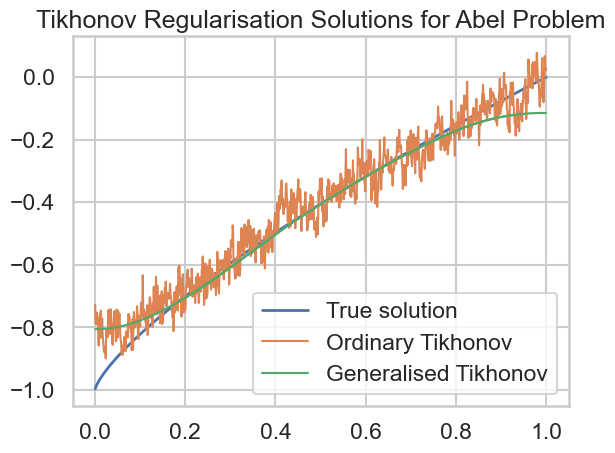

In [82]:
x_alpha_optim_ordinary = df_2c.iloc[idx_ordinary]["x_alpha_ordinary"]
x_alpha_optim_generalised = df_2c.iloc[idx_generalised]["x_alpha_generalised"]
plt.plot(s, x_true, label="True solution", lw=2.0)
plt.plot(s, x_alpha_optim_ordinary, label="Ordinary Tikhonov", lw=1.5)
plt.plot(s, x_alpha_optim_generalised, label="Generalised Tikhonov", lw=1.5)
plt.title("Tikhonov Regularisation Solutions for Abel Problem")
plt.legend()

## 2.d

In [83]:
def tikhonov_ordinary(alpha: float) -> npt.NDArray:
    n = A.shape[1]
    x_alpha = np.linalg.inv(A.T @ A + alpha * np.eye(n)) @ A.T @ y_noisy
    return x_alpha


def tikhonov_generalised_smoothness(alpha: float) -> npt.NDArray:
    # TODO: Derive in report
    n = A.shape[1]
    x_alpha = np.linalg.inv(A.T @ A + alpha * (np.eye(n) + D.T @ D)) @ A.T @ y_noisy
    return x_alpha


def F_1(alpha, x_alpha):
    return np.linalg.norm(A @ x_alpha - y_noisy)


alphas = np.linspace(0, 0.015, 200)
data = []
for alpha in tqdm(alphas):
    x_alpha_ordinary = tikhonov_ordinary(alpha)
    F_1_val_ordinary = F_1(alpha, x_alpha_ordinary)
    x_diff_ordinary = x_alpha_ordinary - x_true

    x_alpha_generalised = tikhonov_generalised_smoothness(alpha)
    F_1_val_generalised = F_1(alpha, x_alpha_generalised)
    x_diff_generalised = x_alpha_generalised - x_true

    data.append(
        {
            "alpha": alpha,
            "F_1_ordinary": F_1_val_ordinary,
            "x_alpha_ordinary": x_alpha_ordinary,
            "x_diff_ordinary": x_diff_ordinary,
            "x_diff_ordinary_L2": np.linalg.norm(x_diff_ordinary),
            "F_1_generalised": F_1_val_generalised,
            "x_alpha_generalised": x_alpha_generalised,
            "x_diff_generalised": x_diff_generalised,
            "x_diff_generalised_L2": np.linalg.norm(x_diff_generalised),
        }
    )

df = pd.DataFrame(data)
df_2d = df.copy()

100%|██████████| 200/200 [00:34<00:00,  5.78it/s]


In [84]:
# Find optimal alpha for ordinary Tikhonov
df_2d["ordinary_search_target"] = df_2d["F_1_ordinary"] - safety_factor * noise_level
idx_ordinary = df_2d["ordinary_search_target"].abs().idxmin()
df_2d["generalised_search_target"] = (
    df_2d["F_1_generalised"] - safety_factor * noise_level
)
idx_generalised = df_2d["generalised_search_target"].abs().idxmin()
idx_ordinary_true = df_2d["x_diff_ordinary_L2"].abs().idxmin()
idx_generalised_true = df_2d["x_diff_generalised_L2"].abs().idxmin()
print(
    f"Optimal alpha (ordinary): Estimate: {df_2d.iloc[idx_ordinary]['alpha']}, True min: {df_2d.iloc[idx_ordinary_true]['alpha']}"
)
print(
    f"Optimal alpha (generalised): Estimate: {df_2d.iloc[idx_generalised]['alpha']}, True min: {df_2d.iloc[idx_generalised_true]['alpha']}"
)

ordinary_estimate_alpha = df_2d.iloc[idx_ordinary]["alpha"]
ordinary_estimate_residual = df_2d.iloc[idx_ordinary]["F_1_ordinary"]
ordinary_estimate_error = df_2d.iloc[idx_ordinary]["x_diff_ordinary_L2"]
generalised_estimate_alpha = df_2d.iloc[idx_generalised]["alpha"]
generalised_estimate_residual = df_2d.iloc[idx_generalised]["F_1_generalised"]
generalised_estimate_error = df_2d.iloc[idx_generalised]["x_diff_generalised_L2"]
ordinary_true_alpha = df_2d.iloc[idx_ordinary_true]["alpha"]
ordinary_true_residual = df_2d.iloc[idx_ordinary_true]["F_1_ordinary"]
ordinary_true_error = df_2d.iloc[idx_ordinary_true]["x_diff_ordinary_L2"]
generalised_true_alpha = df_2d.iloc[idx_generalised_true]["alpha"]
generalised_true_residual = df_2d.iloc[idx_generalised_true]["F_1_generalised"]
generalised_true_error = df_2d.iloc[idx_generalised_true]["x_diff_generalised_L2"]

generalised_best_x = df_2d.iloc[idx_generalised]["x_alpha_generalised"]
generalised_best_alpha = df_2d.iloc[idx_generalised]["alpha"]

Optimal alpha (ordinary): Estimate: 0.015, True min: 0.015
Optimal alpha (generalised): Estimate: 0.00557788944723618, True min: 0.00037688442211055275


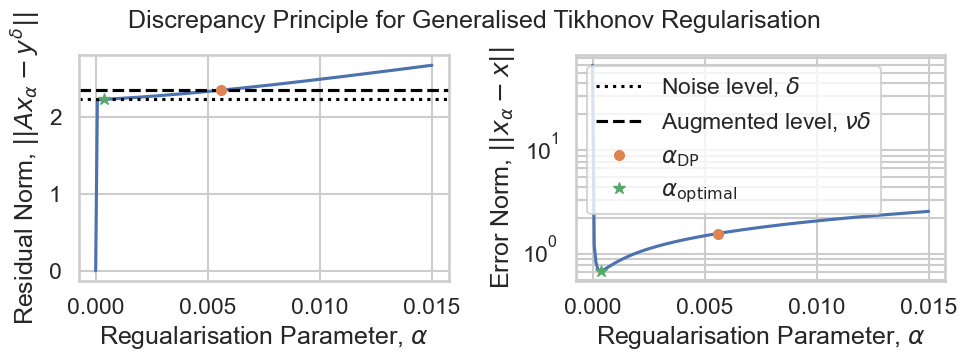

In [85]:
# Discrepancy plot
fig, (ax_resid, ax_error) = plt.subplots(1, 2, figsize=(PAPER_WIDTH_IN, 4.0))

sns.lineplot(ax=ax_resid, data=df_2d, x="alpha", y="F_1_generalised")

ax_resid.axhline(noise_level, color="black", ls=":", label="Noise level, $δ$")
ax_resid.axhline(
    noise_level * safety_factor, color="black", ls="--", label="Augmented level, $νδ$"
)

ax_resid.plot(
    generalised_estimate_alpha,
    generalised_estimate_residual,
    "o",
    color="C1",
    markersize=7,
    label="$α_\\mathrm{DP}$",
)
ax_resid.plot(
    generalised_true_alpha,
    generalised_true_residual,
    "*",
    color="C2",
    markersize=9,
    label="$α_\\mathrm{optimal}$",
)

ax_resid.set_xlabel("Regualarisation Parameter, $α$")
ax_resid.set_ylabel("Residual Norm, $||Ax_α - y^δ||$")

sns.lineplot(ax=ax_error, data=df_2d, x="alpha", y="x_diff_generalised_L2", color="C0")
ax_error.plot(
    generalised_estimate_alpha,
    generalised_estimate_error,
    "o",
    color="C1",
    markersize=7,
)
ax_error.plot(
    generalised_true_alpha, generalised_true_error, "*", color="C2", markersize=9
)
# sns.lineplot(data=dfs, x="alpha", y="x_diff_generalised_L2")
ax_error.set_yscale("log")
ax_error.grid(axis="y", which="both")
ax_error.set_xlabel("Regualarisation Parameter, $α$")
ax_error.set_ylabel("Error Norm, $||x_α - x||$")

# Get legends and handles from both axes
handles1, labels1 = ax_resid.get_legend_handles_labels()
handles2, labels2 = ax_error.get_legend_handles_labels()

handles = [handles1[0]] + handles2 + handles1[1:]
labels = [labels1[0]] + labels2 + labels1[1:]

ax_error.legend(handles, labels)
ax_resid.legend().remove()

fig.suptitle(
    "Discrepancy Principle for Generalised Tikhonov Regularisation", fontsize=TITLE_SIZE_PT, y=0.92
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "2_d.png", dpi=600, bbox_inches="tight")

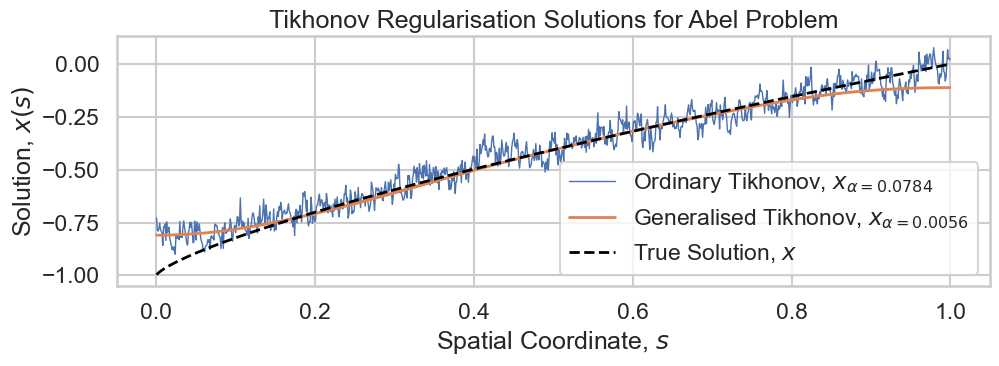

In [88]:
plt.figure(figsize=(PAPER_WIDTH_IN, 4.0))
plt.plot(
    s,
    ordinary_best_x,
    label=f"Ordinary Tikhonov, $x_{{α={ordinary_best_alpha:.4f}}}$",
    lw=1,
)
plt.plot(
    s,
    generalised_best_x,
    label=f"Generalised Tikhonov, $x_{{α={generalised_best_alpha:.4f}}}$",
    lw=2,
)

plt.plot(s, x_true, label="True Solution, $x$", lw=2.0, ls="--", color="black")
plt.legend()

plt.xlabel("Spatial Coordinate, $s$")
plt.ylabel("Solution, $x(s)$")
plt.title("Tikhonov Regularisation Solutions for Abel Problem")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "2_d_solutions.png", dpi=600, bbox_inches="tight")